# 1. Introduction and Objectives
- Forecasting objective
- Tesla stock and target variable
- Forecast horizon: 20 trading days

# 2. Data Collection and Understanding
- Historical data download
- Data inspection
- Data quality checks
- Descriptive statistics

In [1]:
import yfinance as yf
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "src").exists():
    PROJECT_DIR = PROJECT_DIR.parent

# Create stock data directory
DATA_DIR = PROJECT_DIR / "data" / "stock"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Download Tesla historical daily data
tesla = yf.download(
    "TSLA",
    start="2015-01-01",
    interval="1d",
    auto_adjust=True,
    progress=False,
    multi_level_index=False
)

# Save as CSV
csv_path = DATA_DIR / "TSLA_daily.csv"

tesla.to_csv(csv_path)

print("Dataset saved:", csv_path)
print("Dataset shape:", tesla.shape)
print(tesla.head())

Dataset saved: c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\data\stock\TSLA_daily.csv
Dataset shape: (2993, 5)
                Close       High        Low       Open    Volume
Date                                                            
2015-01-02  14.620667  14.883333  14.217333  14.858000  71466000
2015-01-05  14.006000  14.433333  13.810667  14.303333  80527500
2015-01-06  14.085333  14.280000  13.614000  14.004000  93928500
2015-01-07  14.063333  14.318667  13.985333  14.223333  44526000
2015-01-08  14.041333  14.253333  14.000667  14.187333  51637500


In [2]:
print("Shape:", tesla.shape)
print("First 5 rows:")
display(tesla.head())

print("Last 5 rows:")
display(tesla.tail())

print("Missing values:")
print(tesla.isnull().sum())

Shape: (2993, 5)
First 5 rows:


,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,14.620667,14.883333,14.217333,14.858000,71466000
2015-01-05,14.006000,14.433333,13.810667,14.303333,80527500
2015-01-06,14.085333,14.280000,13.614000,14.004000,93928500
2015-01-07,14.063333,14.318667,13.985333,14.223333,44526000
2015-01-08,14.041333,14.253333,14.000667,14.187333,51637500


Last 5 rows:


,Close,High,Low,Open,Volume
Date,,,,,
2026-11-19,374.410004,393.600006,370.809998,389.910004,26532900
2026-11-20,345.820007,373.880005,344.329987,370.429993,46244300
2026-11-23,385.459991,393.829987,371.950012,374.739990,47105900
2026-11-24,384.679993,390.089996,375.500000,383.769989,28697600
2026-11-25,364.839996,370.230011,361.290009,370.230011,3661098


Missing values:
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [3]:
print("Data types:")
print(tesla.dtypes)

print("\nIndex information:")
print("Index type:", type(tesla.index))
print("Date range:", tesla.index.min(), "to", tesla.index.max())

print("\nData integrity:")
print("Duplicate dates:", tesla.index.duplicated().sum())
print("Chronologically sorted:", tesla.index.is_monotonic_increasing)
print("Duplicate rows:", tesla.duplicated().sum())

print("\nDescriptive statistics:")
display(tesla.describe().round(2))

Data types:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Index information:
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Date range: 2015-01-02 00:00:00 to 2026-11-25 00:00:00

Data integrity:
Duplicate dates: 0
Chronologically sorted: True
Duplicate rows: 0

Descriptive statistics:


,Close,High,Low,Open,Volume
count,2993.00,2993.00,2993.00,2993.00,2.993000e+03
mean,156.41,159.76,152.95,156.45,1.062924e+08
std,142.29,145.27,139.28,142.38,7.084611e+07
min,9.58,10.33,9.40,9.49,3.661098e+06
25%,18.79,19.12,18.42,18.76,6.306450e+07
50%,147.43,151.89,144.34,148.20,8.867550e+07
75%,262.46,267.59,257.21,261.69,1.238094e+08
max,489.88,498.83,485.33,489.88,9.140820e+08


# 3. Exploratory Data Analysis (EDA)
- Historical closing prices
- Moving averages
- Daily returns
- Volatility analysis
- EDA findings

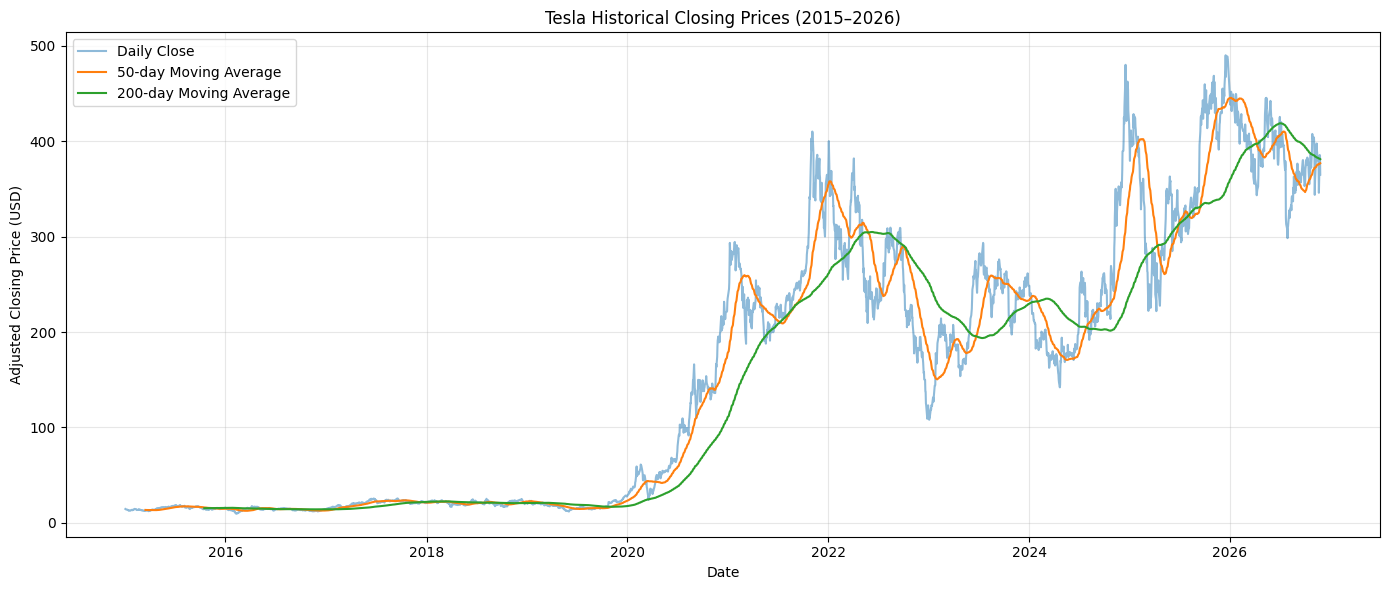

In [4]:
import matplotlib.pyplot as plt

# Extract closing prices
close = tesla["Close"]

# Calculate moving averages
rolling_50 = close.rolling(window=50).mean()
rolling_200 = close.rolling(window=200).mean()

# Plot historical prices and trends
plt.figure(figsize=(14, 6))

plt.plot(close, label="Daily Close", alpha=0.5)
plt.plot(rolling_50, label="50-day Moving Average")
plt.plot(rolling_200, label="200-day Moving Average")

plt.title("Tesla Historical Closing Prices (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

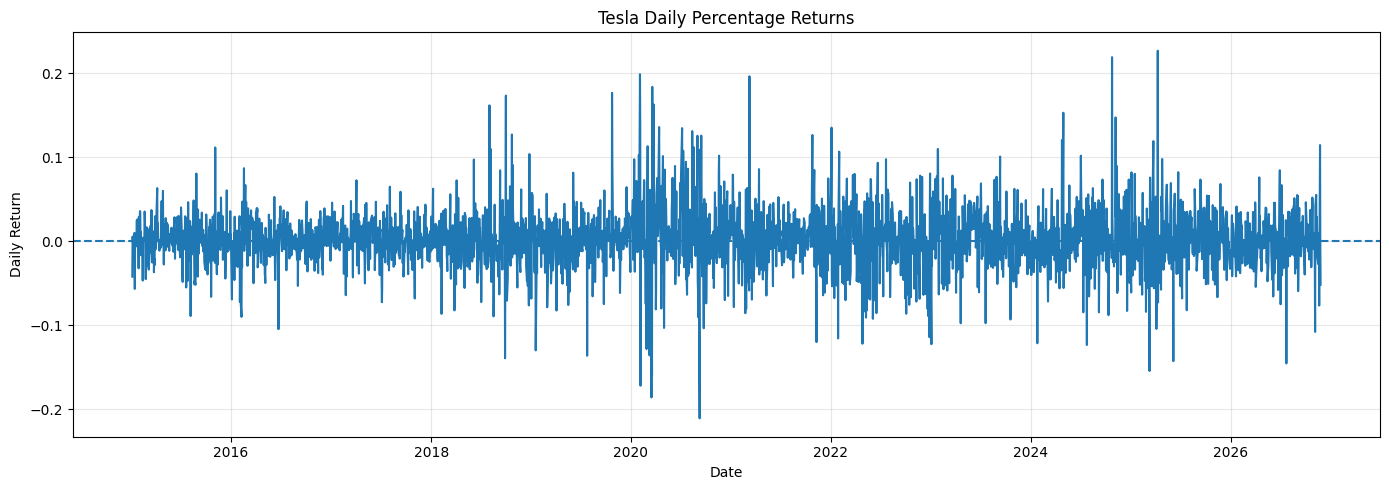

count    2992.0000
mean        0.0017
std         0.0360
min        -0.2106
25%        -0.0167
50%         0.0010
75%         0.0195
max         0.2269
Name: Close, dtype: float64


In [5]:
daily_returns = close.pct_change().dropna()

plt.figure(figsize=(14, 5))

plt.plot(daily_returns)
plt.axhline(y=0, linestyle="--")

plt.title("Tesla Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(daily_returns.describe().round(4))

# 4. Data Preprocessing and Sequence Generation
- Chronological splitting
- MinMax scaling
- Lookback window
- Forecast horizon
- Sequence generation

In [6]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Forecasting configuration
LOOKBACK = 60
HORIZON = 20

# Extract closing prices
close_values = tesla["Close"].values.reshape(-1, 1)

# Chronological split boundaries
n = len(close_values)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = close_values[:train_end]
val_data = close_values[train_end:val_end]
test_data = close_values[val_end:]

print("Total observations:", n)
print("Training observations:", len(train_data))
print("Validation observations:", len(val_data))
print("Testing observations:", len(test_data))

Total observations: 2993
Training observations: 2095
Validation observations: 449
Testing observations: 449


In [7]:
scaler = MinMaxScaler(feature_range=(0, 1))

# Fit only on training data
scaler.fit(train_data)

# Transform the complete series using the fitted scaler
scaled_prices = scaler.transform(close_values)

print("Original training range:",
      train_data.min(), "to", train_data.max())

print("Scaled training range:",
      scaled_prices[:train_end].min(),
      "to",
      scaled_prices[:train_end].max())

Original training range: 9.57800006866455 to 409.9700012207031
Scaled training range: 0.0 to 1.0


In [8]:
print("Dataset shape:", tesla.shape)
print("First date:", tesla.index.min())
print("Last date:", tesla.index.max())
print("Duplicate dates:", tesla.index.duplicated().sum())
print("Chronologically sorted:", tesla.index.is_monotonic_increasing)

Dataset shape: (2993, 5)
First date: 2015-01-02 00:00:00
Last date: 2026-11-25 00:00:00
Duplicate dates: 0
Chronologically sorted: True


In [9]:
def create_sequences(data, start_target, end_target,
                     lookback=60, horizon=20):

    X, y = [], []

    for i in range(start_target, end_target - horizon + 1):

        # Historical observations
        X.append(data[i - lookback:i, 0])

        # Following 20 observations
        y.append(data[i:i + horizon, 0])

    return np.array(X), np.array(y)


# Training sequences
X_train, y_train = create_sequences(
    scaled_prices,
    start_target=LOOKBACK,
    end_target=train_end,
    lookback=LOOKBACK,
    horizon=HORIZON
)

# Validation sequences
X_val, y_val = create_sequences(
    scaled_prices,
    start_target=train_end,
    end_target=val_end,
    lookback=LOOKBACK,
    horizon=HORIZON
)

# Testing sequences
X_test, y_test = create_sequences(
    scaled_prices,
    start_target=val_end,
    end_target=n,
    lookback=LOOKBACK,
    horizon=HORIZON
)


# Add the feature dimension required by GRU
X_train = X_train.reshape(-1, LOOKBACK, 1)
X_val = X_val.reshape(-1, LOOKBACK, 1)
X_test = X_test.reshape(-1, LOOKBACK, 1)


print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (2016, 60, 1) (2016, 20)
Validation: (430, 60, 1) (430, 20)
Testing: (430, 60, 1) (430, 20)


# 5. GRU Model Development
- Architecture
- Model compilation
- Training callbacks
- Model training
- Learning curves

## GRU (Gated Recurrent Unit)

In [10]:
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build GRU model
gru_model = Sequential([
    Input(shape=(LOOKBACK, 1)),

    GRU(64),

    Dropout(0.2),

    Dense(HORIZON)
])

# Compile
gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display architecture
gru_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,164 (55.33 KB)

 Trainable params: 14,164 (55.33 KB)

 Non-trainable params: 0 (0.00 B)

### 1. Configure training callbacks

In [11]:
from pathlib import Path

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = MODEL_DIR / "best_tesla_gru.keras"

callbacks = [
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

### 2. Train the model

In [12]:
history = gru_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=50,
    batch_size=32,

    callbacks=callbacks,

    shuffle=True,
    verbose=1
)

Epoch 1/50
59/63 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0368 - mae: 0.1184
Epoch 1: val_loss improved from None to 0.00892, saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\best_tesla_gru.keras

Epoch 1: finished saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\best_tesla_gru.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0350 - mae: 0.1143 - val_loss: 0.0089 - val_mae: 0.0695 - learning_rate: 0.0010
Epoch 2/50
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0065 - mae: 0.0471
Epoch 2: val_loss did not improve from 0.00892
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0065 - mae: 0.0470 - val_loss: 0.0097 - val_mae: 0.0721 - learning_rate: 0.0010
Epoch 3/50
60/63 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0051 - mae: 0.0399
Epoch 3: val_loss improved from 0.00892 to 0.00778, saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\best_tesla_gru.keras

Ep

### 3. Inspect the learning curves

Best epoch: 16
Best validation loss: 0.00632234662771225
Validation MAE at best epoch: 0.0568210743367672


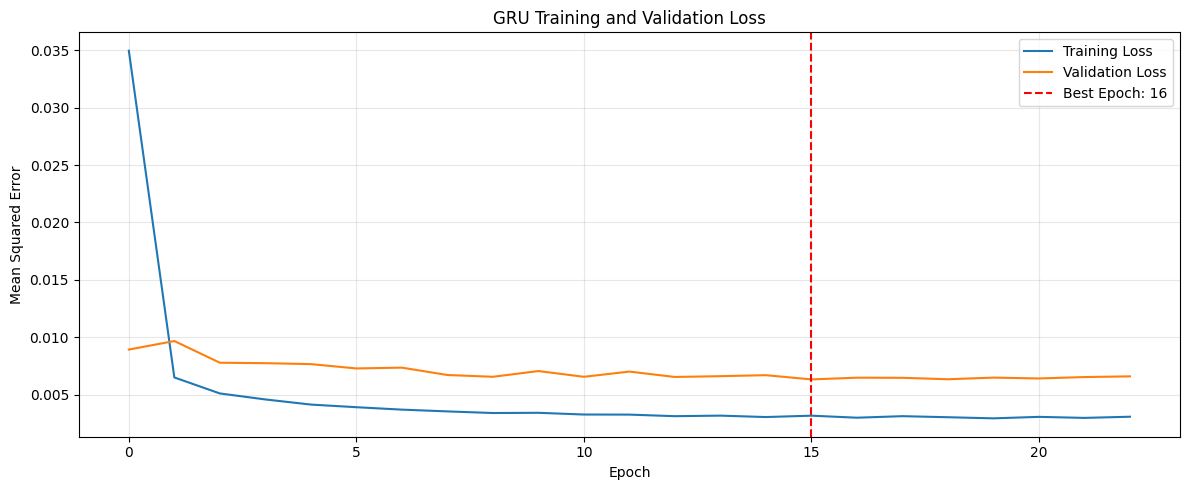

In [13]:
import matplotlib.pyplot as plt
import numpy as np

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))
print("Validation MAE at best epoch:",
      history.history["val_mae"][best_epoch - 1])

plt.figure(figsize=(12, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("GRU Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This suggests the model learned quickly, followed by limited improvements in generalization.

In [14]:
best_gru = tf.keras.models.load_model(checkpoint_path)

print("Best GRU checkpoint loaded successfully.")

Best GRU checkpoint loaded successfully.


### 4. Evaluate on unseen test data

In [15]:
# Predictions in scaled units
y_pred_scaled = best_gru.predict(X_test)

# Convert predictions and actual values back to USD
y_pred = scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

y_true = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(-1, HORIZON)

print("Predictions shape:", y_pred.shape)
print("Actual values shape:", y_true.shape)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
Predictions shape: (430, 20)
Actual values shape: (430, 20)


# 6. Model Evaluation and Baseline Comparison
- Test-set evaluation
- Naive persistence baseline
- Forecast horizon errors
- Validation comparison
- Interpretation and limitations

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    y_true.flatten(),
    y_pred.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        y_true.flatten(),
        y_pred.flatten()
    )
)

print(f"Test MAE:  ${mae:.2f}")
print(f"Test RMSE: ${rmse:.2f}")

Test MAE:  $27.35
Test RMSE: $35.99


### Compare against a naive baseline

In [17]:
# Last observed price in each input window
last_prices_scaled = X_test[:, -1, 0]

# Repeat the last price across all 20 forecast days
baseline_scaled = np.repeat(
    last_prices_scaled.reshape(-1, 1),
    HORIZON,
    axis=1
)

# Convert to USD
baseline_pred = scaler.inverse_transform(
    baseline_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

baseline_mae = mean_absolute_error(
    y_true.flatten(),
    baseline_pred.flatten()
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_true.flatten(),
        baseline_pred.flatten()
    )
)

print(f"GRU MAE:      ${mae:.2f}")
print(f"Baseline MAE: ${baseline_mae:.2f}")

print(f"GRU RMSE:      ${rmse:.2f}")
print(f"Baseline RMSE: ${baseline_rmse:.2f}")

GRU MAE:      $27.35
Baseline MAE: $24.94
GRU RMSE:      $35.99
Baseline RMSE: $33.75


The baseline has lower errors on both metrics.

This means that, on our current test evaluation, simply repeating the last observed closing price performs better than our GRU.

### Investigate where the GRU struggles

In [19]:
# Absolute errors for each forecast horizon
gru_errors = np.abs(y_true - y_pred)
baseline_errors = np.abs(y_true - baseline_pred)

gru_mae_by_horizon = gru_errors.mean(axis=0)
baseline_mae_by_horizon = baseline_errors.mean(axis=0)

gru_rmse_by_horizon = np.sqrt((gru_errors ** 2).mean(axis=0))
baseline_rmse_by_horizon = np.sqrt((baseline_errors ** 2).mean(axis=0))

# Display comparison
import pandas as pd

horizon_results = pd.DataFrame({
    "Forecast_Day": np.arange(1, HORIZON + 1),
    "GRU_MAE": gru_mae_by_horizon,
    "Baseline_MAE": baseline_mae_by_horizon,
    "GRU_RMSE": gru_rmse_by_horizon,
    "Baseline_RMSE": baseline_rmse_by_horizon
})

print(horizon_results.round(2).to_string(index=False))

 Forecast_Day  GRU_MAE  Baseline_MAE  GRU_RMSE  Baseline_RMSE
            1    15.26          9.11     18.88          11.97
            2    16.36         12.51     20.46          16.38
            3    19.37         15.11     24.25          19.74
            4    19.99         17.52     25.43          22.51
            5    21.97         19.34     27.97          24.69
            6    23.57         20.93     29.75          27.04
            7    25.41         22.54     31.77          29.09
            8    25.90         23.68     32.86          30.63
            9    25.84         24.64     33.22          32.11
           10    27.89         25.87     35.33          33.41
           11    29.05         26.88     36.58          34.76
           12    30.24         28.10     38.13          36.05
           13    30.07         29.05     38.61          37.38
           14    31.14         30.16     40.23          38.79
           15    33.08         30.76     42.47          40.09
        

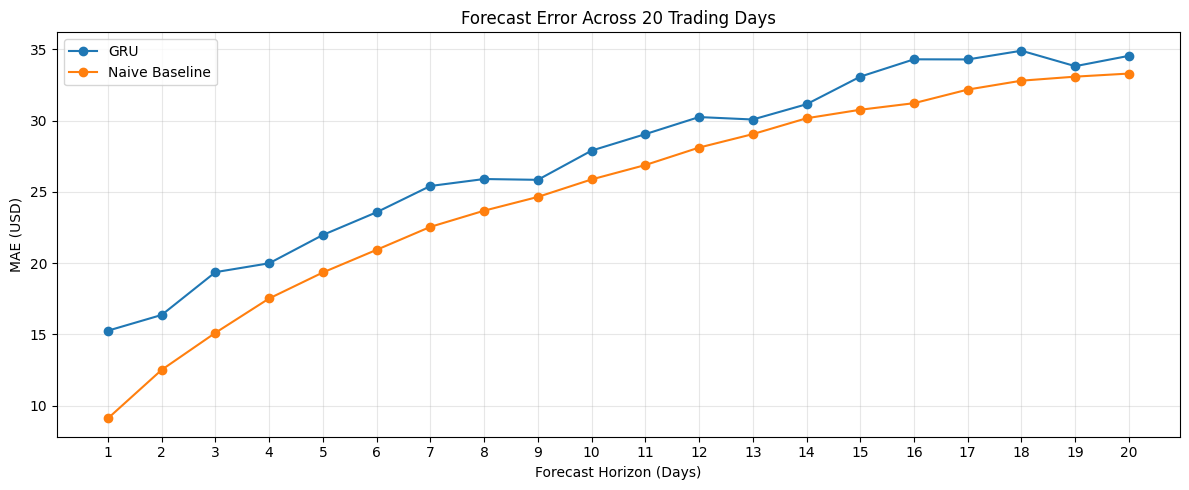

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    horizon_results["Forecast_Day"],
    horizon_results["GRU_MAE"],
    marker="o",
    label="GRU"
)

plt.plot(
    horizon_results["Forecast_Day"],
    horizon_results["Baseline_MAE"],
    marker="o",
    label="Naive Baseline"
)

plt.title("Forecast Error Across 20 Trading Days")
plt.xlabel("Forecast Horizon (Days)")
plt.ylabel("MAE (USD)")
plt.xticks(range(1, 21))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:**

The current GRU has not demonstrated predictive value beyond simply carrying forward the last observed price.

This doesn't mean GRUs are unsuitable for financial forecasting. It means this particular model, configuration and dataset have not produced an improvement.

### Validation comparison

In [21]:
# Predict validation sequences
y_val_pred_scaled = best_gru.predict(X_val)

# Inverse transformation
y_val_pred = scaler.inverse_transform(
    y_val_pred_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

y_val_true = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(-1, HORIZON)

# Naive persistence baseline
val_last_prices = X_val[:, -1, 0]

val_baseline_scaled = np.repeat(
    val_last_prices.reshape(-1, 1),
    HORIZON,
    axis=1
)

val_baseline_pred = scaler.inverse_transform(
    val_baseline_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

# Metrics
val_gru_mae = mean_absolute_error(
    y_val_true.flatten(),
    y_val_pred.flatten()
)

val_baseline_mae = mean_absolute_error(
    y_val_true.flatten(),
    val_baseline_pred.flatten()
)

val_gru_rmse = np.sqrt(mean_squared_error(
    y_val_true.flatten(),
    val_gru_pred.flatten()
)) if False else np.sqrt(mean_squared_error(
    y_val_true.flatten(),
    y_val_pred.flatten()
))

val_baseline_rmse = np.sqrt(mean_squared_error(
    y_val_true.flatten(),
    val_baseline_pred.flatten()
))

print(f"Validation GRU MAE:      ${val_gru_mae:.2f}")
print(f"Validation baseline MAE: ${val_baseline_mae:.2f}")
print(f"Validation GRU RMSE:      ${val_gru_rmse:.2f}")
print(f"Validation baseline RMSE: ${val_baseline_rmse:.2f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Validation GRU MAE:      $22.75
Validation baseline MAE: $22.37
Validation GRU RMSE:      $31.84
Validation baseline RMSE: $31.51


The GRU nearly matches the naive baseline on validation, but generalizes less effectively on the test period. We have no evidence that it adds predictive value over the baseline

In [22]:
print("Latest available date:", tesla.index[-1])
print("Latest closing price:", tesla["Close"].iloc[-1])

print("Checkpoint exists:", checkpoint_path.exists())
print("Dataset exists:", csv_path.exists())

Latest available date: 2026-11-25 00:00:00
Latest closing price: 364.8399963378906
Checkpoint exists: True
Dataset exists: True


# 7. Final Model Training and Saving
- Refit scaler on all available data
- Generate complete training sequences
- Train final GRU
- Save model and scaler

### Retrain the final GRU

In [23]:
import joblib

# Fit scaler on the complete historical dataset
final_scaler = MinMaxScaler(feature_range=(0, 1))

final_scaled_prices = final_scaler.fit_transform(close_values)

print("Final scaler fitted.")
print("Scaled range:",
      final_scaled_prices.min(),
      "to",
      final_scaled_prices.max())

Final scaler fitted.
Scaled range: 0.0 to 1.0


In [24]:
# Generate the complete training sequences
X_full, y_full = create_sequences(
    final_scaled_prices,
    start_target=LOOKBACK,
    end_target=len(final_scaled_prices),
    lookback=LOOKBACK,
    horizon=HORIZON
)

X_full = X_full.reshape(-1, LOOKBACK, 1)

print("Full training input:", X_full.shape)
print("Full training target:", y_full.shape)


Full training input: (2914, 60, 1)
Full training target: (2914, 20)


In [25]:
# Build the final GRU
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

final_gru = Sequential([
    Input(shape=(LOOKBACK, 1)),
    GRU(64),
    Dropout(0.2),
    Dense(HORIZON)
])

final_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

final_gru.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,164 (55.33 KB)

 Trainable params: 14,164 (55.33 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
final_history = final_gru.fit(
    X_full,
    y_full,
    epochs=16,
    batch_size=32,
    shuffle=True,
    verbose=1
)

Epoch 1/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.0401 - mae: 0.1280
Epoch 2/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0073 - mae: 0.0554
Epoch 3/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0062 - mae: 0.0499
Epoch 4/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0055 - mae: 0.0465
Epoch 5/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0050 - mae: 0.0448
Epoch 6/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.0045 - mae: 0.0426
Epoch 7/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0044 - mae: 0.0417
Epoch 8/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0044 - mae: 0.0418
Epoch 9/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0041 - mae: 0.0399
Epoch 10/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0040 - mae: 0.0400
Epoch 11/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0039 - mae: 0.0394
Epoch 12/16
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0037 - mae: 0.0379
Epoch 13/16
92/92 ━━━━━━━━━━━━━━━━━━━

In [27]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

final_model_path = MODEL_DIR / "tesla_gru_final.keras"
final_scaler_path = MODEL_DIR / "tesla_scaler.pkl"

final_gru.save(final_model_path)

joblib.dump(final_scaler, final_scaler_path)

print("Final model saved:", final_model_path)
print("Final scaler saved:", final_scaler_path)

Final model saved: c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\tesla_gru_final.keras
Final scaler saved: c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\tesla_scaler.pkl


# 8. Forecasting the Next 20 Trading Days
- Load or use final model
- Generate predictions
- Generate NYSE trading dates
- Forecast visualization

### Generate the next 20 trading-day forecasts

In [28]:
# Select the latest 60 closing prices
last_60_days = final_scaled_prices[-LOOKBACK:]

# Add batch dimension
last_60_days = last_60_days.reshape(1, LOOKBACK, 1)

print("Forecast input shape:", last_60_days.shape)

Forecast input shape: (1, 60, 1)


In [29]:
# Generate predictions
future_scaled = final_gru.predict(last_60_days)

# Convert predictions back to USD
future_prices = final_scaler.inverse_transform(
    future_scaled.reshape(-1, 1)
).flatten()

print("Forecast shape:", future_prices.shape)
print("First predicted price:", round(future_prices[0], 2))
print("Last predicted price:", round(future_prices[-1], 2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step
Forecast shape: (20,)
First predicted price: 374.76
Last predicted price: 365.9


In [30]:
%pip install pandas-market-calendars


   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   ---------------------------------------- 0/5 [toolz]
   -------- ------------------------------- 1/5 [pyluach]
   -------- ------------------------------- 1/5 [pyluach]
   ---------------- ----------------------- 2/5 [korean_lunar_calendar]
   ------------------------ --------------- 3/5 [exchange-calendars]
   ------------------------ --------------- 3/5 [exchange-calendars]
   ------------------------ --------------- 3/5 [exchange-calendars]
   ------------------------ --------------- 3/5 [exchange-calendars]
   ------------------------ ---


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import pandas_market_calendars as mcal

nyse = mcal.get_calendar("NYSE")

last_date = tesla.index[-1]

schedule = nyse.schedule(
    start_date=last_date + pd.Timedelta(days=1),
    end_date=last_date + pd.Timedelta(days=45)
)

future_dates = schedule.index[:HORIZON]

assert len(future_dates) == HORIZON

print("Last historical date:", last_date)
print("First forecast date:", future_dates[0])
print("Last forecast date:", future_dates[-1])

Last historical date: 2026-11-25 00:00:00
First forecast date: 2026-11-27 00:00:00
Last forecast date: 2026-12-24 00:00:00


In [32]:
forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Close": future_prices
})

forecast_df["Predicted_Close"] = (
    forecast_df["Predicted_Close"].round(2)
)

print(forecast_df.to_string(index=False))

      Date  Predicted_Close
2026-11-27       374.760010
2026-11-30       369.920013
2026-12-01       373.500000
2026-12-02       371.619995
2026-12-03       371.230011
2026-12-04       374.209991
2026-12-07       375.029999
2026-12-08       370.459991
2026-12-09       365.859985
2026-12-10       372.390015
2026-12-11       369.350006
2026-12-14       370.220001
2026-12-15       371.269989
2026-12-16       370.399994
2026-12-17       368.149994
2026-12-18       371.350006
2026-12-21       371.609985
2026-12-22       369.149994
2026-12-23       366.149994
2026-12-24       365.899994


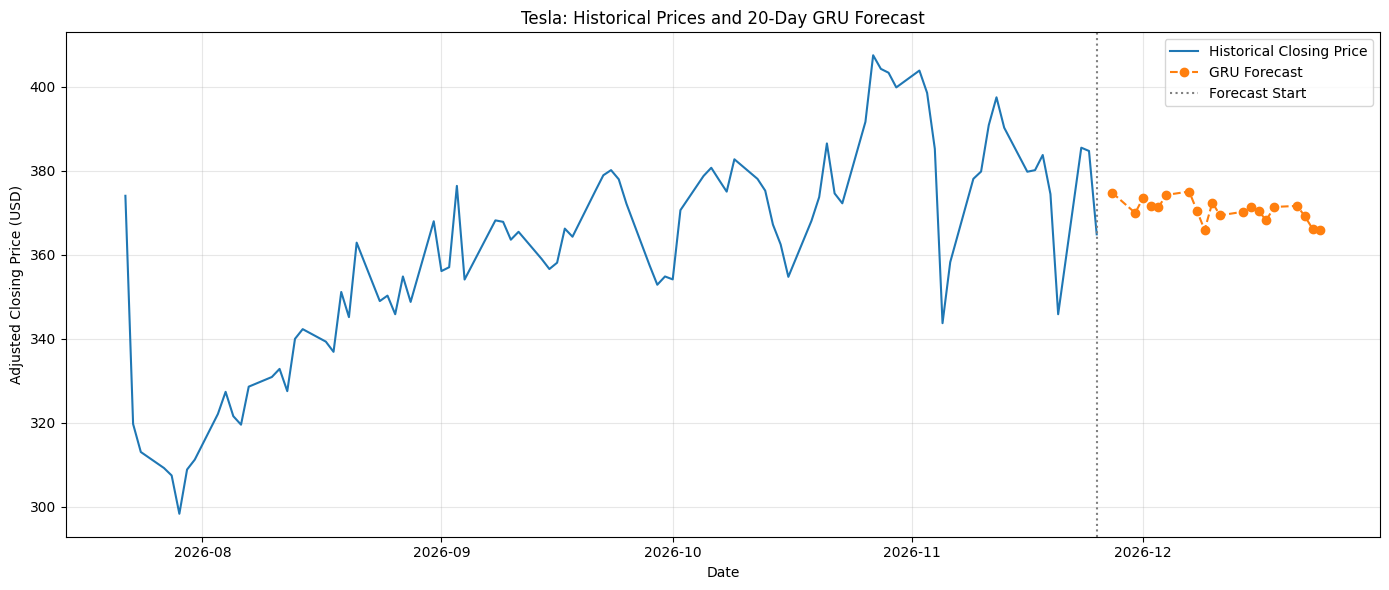

In [33]:
plt.figure(figsize=(14, 6))

# Last 90 historical trading days
historical = tesla["Close"].tail(90)

plt.plot(
    historical.index,
    historical.values,
    label="Historical Closing Price"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_Close"],
    marker="o",
    linestyle="--",
    label="GRU Forecast"
)

plt.axvline(
    x=last_date,
    color="gray",
    linestyle=":",
    label="Forecast Start"
)

plt.title("Tesla: Historical Prices and 20-Day GRU Forecast")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import load_model

# Project paths
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "src").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "stock"
MODEL_DIR = PROJECT_DIR / "models"

# Load historical data
tesla = pd.read_csv(
    DATA_DIR / "TSLA_daily.csv",
    index_col=0,
    parse_dates=True
)

# Load final model and its corresponding scaler
final_gru = load_model(
    MODEL_DIR / "tesla_gru_final.keras"
)

final_scaler = joblib.load(
    MODEL_DIR / "tesla_scaler.pkl"
)

# Configuration
LOOKBACK = 60
HORIZON = 20

print("Recovery successful!")
print("Dataset:", tesla.shape)
print("Final model loaded.")
print("Scaler loaded.")

Recovery successful!
Dataset: (2993, 5)
Final model loaded.
Scaler loaded.


In [2]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from pathlib import Path
from math import ceil

# 1. Reconstruct the original chronological split
close_values = tesla["Close"].values.reshape(-1, 1)

n = len(close_values)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = close_values[:train_end]

# 2. Fit the ORIGINAL scaler on training data only
evaluation_scaler = MinMaxScaler(feature_range=(0, 1))
evaluation_scaler.fit(train_data)

scaled_prices = evaluation_scaler.transform(close_values)

# 3. Recreate the sequence-generation function
def create_sequences(
    data,
    start_target,
    end_target,
    lookback=60,
    horizon=20
):
    X, y = [], []

    for i in range(start_target, end_target - horizon + 1):
        X.append(data[i-lookback:i, 0])
        y.append(data[i:i+horizon, 0])

    return np.array(X), np.array(y)


# 4. Reconstruct validation and test sequences
X_val, y_val = create_sequences(
    scaled_prices, train_end, val_end, LOOKBACK, HORIZON
)

X_test, y_test = create_sequences(
    scaled_prices, val_end, n, LOOKBACK, HORIZON
)

X_val = X_val.reshape(-1, LOOKBACK, 1)
X_test = X_test.reshape(-1, LOOKBACK, 1)

# 5. Load the original best-validation checkpoint
best_gru = tf.keras.models.load_model(
    MODEL_DIR / "best_tesla_gru.keras"
)

print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Original evaluation model loaded.")


Validation: (430, 60, 1) (430, 20)
Test: (430, 60, 1) (430, 20)
Original evaluation model loaded.


# 9. Statistical Uncertainty and Forecast Reliability
- Prediction intervals
- Interval coverage
- Interval width
- Rolling-origin backtesting
- Statistical interpretation

### Estimate the prediction errors

In [3]:

# Generate predictions
val_pred_scaled = best_gru.predict(X_val, verbose=0)
test_pred_scaled = best_gru.predict(X_test, verbose=0)

# Convert scaled values back to USD
val_actual = evaluation_scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(-1, HORIZON)

val_pred = evaluation_scaler.inverse_transform(
    val_pred_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

test_actual = evaluation_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(-1, HORIZON)

test_pred = evaluation_scaler.inverse_transform(
    test_pred_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

# Calibration residuals
val_residuals = val_actual - val_pred

# Test residuals
test_residuals = test_actual - test_pred

print("Validation predictions:", val_pred.shape)
print("Test predictions:", test_pred.shape)
print("Residuals reconstructed successfully.")


Validation predictions: (430, 20)
Test predictions: (430, 20)
Residuals reconstructed successfully.


### Construct provisional 90% prediction intervals

In [4]:

alpha = 0.10
n_calibration = len(val_residuals)

# Finite-sample conformal quantile index
k = ceil((n_calibration + 1) * (1 - alpha))

if k > n_calibration:
    raise ValueError("Not enough calibration observations.")

# Horizon-specific absolute error quantiles
absolute_val_errors = np.abs(val_residuals)

sorted_errors = np.sort(absolute_val_errors, axis=0)

q_horizon = sorted_errors[k - 1, :]

# Prediction intervals on the test set
lower_test = test_pred - q_horizon
upper_test = test_pred + q_horizon

# Empirical coverage for each horizon
test_coverage = np.mean(
    (test_actual >= lower_test) &
    (test_actual <= upper_test),
    axis=0
)

# Average interval width
interval_width = upper_test - lower_test

results = pd.DataFrame({
    "Forecast_Day": np.arange(1, HORIZON + 1),
    "Calibration_Error_Quantile": q_horizon,
    "Test_Coverage": test_coverage,
    "Mean_Interval_Width_USD": interval_width.mean(axis=0)
})

print(results.round(3).to_string(index=False))

print(
    "\nOverall test coverage:",
    round(np.mean(
        (test_actual >= lower_test) &
        (test_actual <= upper_test)
    ) * 100, 2),
    "%"
)


 Forecast_Day  Calibration_Error_Quantile  Test_Coverage  Mean_Interval_Width_USD
            1                      19.717          0.681                   39.435
            2                      24.556          0.774                   49.113
            3                      29.987          0.788                   59.975
            4                      31.281          0.791                   62.562
            5                      34.428          0.781                   68.855
            6                      34.887          0.770                   69.775
            7                      37.951          0.760                   75.903
            8                      41.607          0.800                   83.214
            9                      46.151          0.842                   92.301
           10                      50.755          0.849                  101.509
           11                      52.337          0.858                  104.674
           12   

Our intervals are under-covering: actual prices fall outside them more frequently than the nominal 10% outside rate.

But there's an interesting pattern.
- Day 1 coverage: 68.1%.
- Day 10 coverage: 84.9%.
- Day 20 coverage: 85.6%.
The first few forecast horizons are particularly difficult.

The interval widths also increase from approximately $39 on day 1 to $138 on day 20. That makes sense: uncertainty generally accumulates as we forecast further into the future.

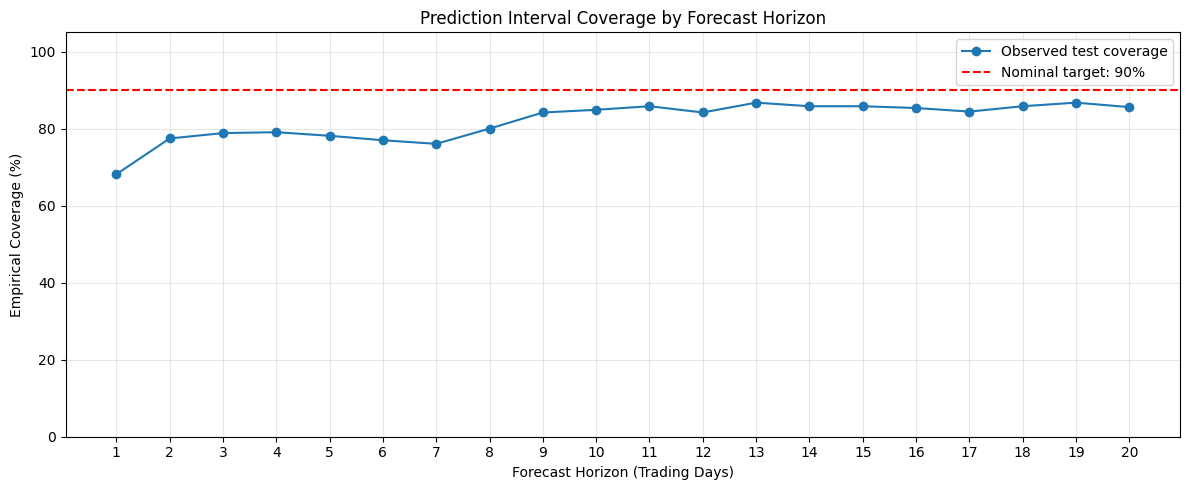

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    results["Forecast_Day"],
    results["Test_Coverage"] * 100,
    marker="o",
    label="Observed test coverage"
)

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    label="Nominal target: 90%"
)

plt.xlabel("Forecast Horizon (Trading Days)")
plt.ylabel("Empirical Coverage (%)")
plt.title("Prediction Interval Coverage by Forecast Horizon")
plt.xticks(range(1, 21))
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [6]:

# Residual bias by forecast horizon
# Residual = Actual - Predicted

bias_results = pd.DataFrame({
    "Forecast_Day": np.arange(1, HORIZON + 1),
    "Validation_Mean_Error": val_residuals.mean(axis=0),
    "Validation_Median_Error": np.median(val_residuals, axis=0),
    "Test_Mean_Error": test_residuals.mean(axis=0),
    "Test_Median_Error": np.median(test_residuals, axis=0)
})

print(bias_results.round(2).to_string(index=False))

print("\nOverall validation bias:",
      round(val_residuals.mean(), 2), "USD")

print("Overall test bias:",
      round(test_residuals.mean(), 2), "USD")


 Forecast_Day  Validation_Mean_Error  Validation_Median_Error  Test_Mean_Error  Test_Median_Error
            1                  -2.34                    -4.43            10.89              11.32
            2                  -2.94                    -5.03             9.75              10.20
            3                  -1.56                    -4.70            11.16              12.06
            4                  -0.72                    -3.92            10.63              10.61
            5                  -0.36                    -2.92            12.20              11.92
            6                   0.92                    -2.33            11.76              12.67
            7                  -0.04                    -3.38            13.05              14.83
            8                   0.79                    -1.52            13.17              14.43
            9                   2.79                     0.05            11.24              12.52
           10       

Look at the pattern:
- Validation days 1–5: the GRU generally overpredicts slightly.
- Validation days 15–20: it increasingly underpredicts.
- Test days 1–20: mean errors are positive throughout.
- Test day 20: mean underprediction is approximately $20.94.
This is not just random error around zero.

Our model appears to have struggled to adapt to the price behaviour in the test period.

However, we should be careful: the difference between validation and test bias is evidence of a change in predictive behaviour, not proof of a particular cause.

In [7]:

# Calculate horizon-specific residual quantiles
residual_quantiles = pd.DataFrame({
    "Forecast_Day": np.arange(1, HORIZON + 1),
    "Q05": np.quantile(val_residuals, 0.05, axis=0),
    "Q25": np.quantile(val_residuals, 0.25, axis=0),
    "Median": np.quantile(val_residuals, 0.50, axis=0),
    "Q75": np.quantile(val_residuals, 0.75, axis=0),
    "Q95": np.quantile(val_residuals, 0.95, axis=0)
})

print(residual_quantiles.round(2).to_string(index=False))


 Forecast_Day    Q05    Q25  Median   Q75   Q95
            1 -18.79  -9.39   -4.43  1.92 20.73
            2 -22.92 -11.55   -5.03  3.26 25.24
            3 -27.09 -12.57   -4.70  6.63 34.59
            4 -28.25 -12.71   -3.92  7.93 38.17
            5 -30.24 -13.42   -2.92  9.99 40.76
            6 -32.01 -15.03   -2.33 12.95 40.94
            7 -34.15 -17.25   -3.38 13.09 48.90
            8 -37.16 -18.16   -1.52 15.26 53.98
            9 -38.08 -18.43    0.05 18.06 54.47
           10 -42.96 -20.06   -1.12 18.37 59.00
           11 -43.70 -18.87    0.14 20.01 62.87
           12 -45.25 -19.11    0.96 20.34 63.19
           13 -46.71 -20.12    0.80 19.23 69.52
           14 -47.91 -18.84    1.27 20.77 74.45
           15 -47.45 -17.98    2.34 23.02 78.59
           16 -48.17 -18.47    3.58 24.73 84.55
           17 -50.14 -19.33    0.77 25.02 86.88
           18 -47.81 -19.13    2.29 26.59 85.67
           19 -49.81 -19.94    2.92 26.83 92.87
           20 -51.26 -21.02    2.10 27.5

An important finding from the quantiles:
- The residuals are asymmetric. For example, on forecast day 20, the median residual is +$2.10, but the 5th and 95th percentiles are −$51.26 and +$90.96.
- Uncertainty increases with the forecast horizon. The central 90% residual range grows from about $39.52 on day 1 to $142.22 on day 20.
- The residual distribution shifts upward. Its median moves from negative values in the early forecast days to mostly positive values later. Since residual = actual − predicted, positive values indicate underprediction.

### EXPERIMENT 1: Chronological data partitioning

In [8]:

# EXPERIMENT 1: Chronological data partitioning
# This experiment does not overwrite any existing model or scaler.

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 1. Define chronological boundaries
exp_close = tesla["Close"].values.reshape(-1, 1)
exp_n = len(exp_close)

exp_train_end = int(exp_n * 0.60)
exp_val_end = int(exp_n * 0.70)
exp_cal_end = int(exp_n * 0.85)

print("Total observations:", exp_n)
print("Training ends at:", exp_train_end)
print("Validation ends at:", exp_val_end)
print("Calibration ends at:", exp_cal_end)

# 2. Fit scaler ONLY on training observations
exp_scaler = MinMaxScaler(feature_range=(0, 1))
exp_scaler.fit(exp_close[:exp_train_end])

exp_scaled = exp_scaler.transform(exp_close)

# 3. Generate sequences for each partition
exp_X_train, exp_y_train = create_sequences(
    exp_scaled, LOOKBACK, exp_train_end, LOOKBACK, HORIZON
)

exp_X_val, exp_y_val = create_sequences(
    exp_scaled, exp_train_end, exp_val_end, LOOKBACK, HORIZON
)

exp_X_cal, exp_y_cal = create_sequences(
    exp_scaled, exp_val_end, exp_cal_end, LOOKBACK, HORIZON
)

exp_X_test, exp_y_test = create_sequences(
    exp_scaled, exp_cal_end, exp_n, LOOKBACK, HORIZON
)

# 4. Reshape inputs for the GRU
exp_X_train = exp_X_train.reshape(-1, LOOKBACK, 1)
exp_X_val = exp_X_val.reshape(-1, LOOKBACK, 1)
exp_X_cal = exp_X_cal.reshape(-1, LOOKBACK, 1)
exp_X_test = exp_X_test.reshape(-1, LOOKBACK, 1)

# 5. Inspect partition sizes
print("\nSequence shapes:")
print("Training:   ", exp_X_train.shape, exp_y_train.shape)
print("Validation: ", exp_X_val.shape, exp_y_val.shape)
print("Calibration:", exp_X_cal.shape, exp_y_cal.shape)
print("Test:       ", exp_X_test.shape, exp_y_test.shape)

# 6. Basic integrity checks
assert len(exp_X_train) > 0
assert len(exp_X_val) > 0
assert len(exp_X_cal) > 0
assert len(exp_X_test) > 0

assert exp_train_end < exp_val_end < exp_cal_end < exp_n

print("\nChronological partitioning successful.")


Total observations: 2993
Training ends at: 1795
Validation ends at: 2095
Calibration ends at: 2544

Sequence shapes:
Training:    (1716, 60, 1) (1716, 20)
Validation:  (281, 60, 1) (281, 20)
Calibration: (430, 60, 1) (430, 20)
Test:        (430, 60, 1) (430, 20)

Chronological partitioning successful.


### EXPERIMENT 2: Train GRU with 60/10/15/15 split


In [9]:

# EXPERIMENT 2: Train GRU with 60/10/15/15 split

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, GRU, Dropout, Dense
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Separate experiment checkpoint
exp_model_path = MODEL_DIR / "tesla_gru_calibration_experiment.keras"

# Build the same architecture as the original GRU
exp_gru = Sequential([
    Input(shape=(LOOKBACK, 1)),
    GRU(64),
    Dropout(0.2),
    Dense(HORIZON)
])

exp_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Experiment-specific callbacks
exp_callbacks = [
    ModelCheckpoint(
        filepath=exp_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# Train
exp_history = exp_gru.fit(
    exp_X_train,
    exp_y_train,
    validation_data=(exp_X_val, exp_y_val),
    epochs=50,
    batch_size=32,
    callbacks=exp_callbacks,
    shuffle=True,
    verbose=1
)

# Load the best checkpoint explicitly
exp_best_gru = load_model(exp_model_path)

best_epoch = np.argmin(exp_history.history["val_loss"]) + 1

print("\nExperimental GRU training completed.")
print("Best epoch:", best_epoch)
print("Best validation loss:",
      round(min(exp_history.history["val_loss"]), 6))
print("Checkpoint:", exp_model_path)


Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0271 - mae: 0.0932
Epoch 1: val_loss improved from None to 0.01024, saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\tesla_gru_calibration_experiment.keras

Epoch 1: finished saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\tesla_gru_calibration_experiment.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - loss: 0.0271 - mae: 0.0932 - val_loss: 0.0102 - val_mae: 0.0778 - learning_rate: 0.0010
Epoch 2/50
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0046 - mae: 0.0353
Epoch 2: val_loss improved from 0.01024 to 0.00864, saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\tesla_gru_calibration_experiment.keras

Epoch 2: finished saving model to c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\models\tesla_gru_calibration_experiment.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0046 - ma

### EXPERIMENT 3: Calibration predictions and asymmetric intervals


In [10]:

# EXPERIMENT 3: Calibration predictions and asymmetric intervals

# 1. Predict on calibration data
exp_cal_pred_scaled = exp_best_gru.predict(
    exp_X_cal, verbose=0
)

# 2. Convert predictions and actual values to dollars
exp_cal_actual = exp_scaler.inverse_transform(
    exp_y_cal.reshape(-1, 1)
).reshape(-1, HORIZON)

exp_cal_pred = exp_scaler.inverse_transform(
    exp_cal_pred_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

# 3. Calculate calibration residuals
exp_cal_residuals = exp_cal_actual - exp_cal_pred

# 4. Estimate horizon-specific residual quantiles
exp_q05 = np.quantile(exp_cal_residuals, 0.05, axis=0)
exp_q50 = np.quantile(exp_cal_residuals, 0.50, axis=0)
exp_q95 = np.quantile(exp_cal_residuals, 0.95, axis=0)

# 5. Display calibration statistics
exp_calibration_summary = pd.DataFrame({
    "Forecast_Day": np.arange(1, HORIZON + 1),
    "Q05": exp_q05,
    "Median": exp_q50,
    "Q95": exp_q95,
    "Interval_Width": exp_q95 - exp_q05
})

print("Calibration residual statistics ($):")
print(exp_calibration_summary.round(2).to_string(index=False))

# 6. Overall calibration diagnostics
print("\nOverall calibration diagnostics:")
print("Mean residual: $", round(exp_cal_residuals.mean(), 2))
print("Median residual: $", round(np.median(exp_cal_residuals), 2))
print("Mean absolute error: $", round(
    np.mean(np.abs(exp_cal_residuals)), 2
))


Calibration residual statistics ($):
 Forecast_Day    Q05  Median   Q95  Interval_Width
            1 -10.23    4.30 36.84           47.08
            2 -15.53    1.72 35.25           50.78
            3 -18.76    3.23 45.74           64.50
            4 -21.02    3.61 48.92           69.94
            5 -22.38    3.57 50.00           72.38
            6 -26.07    2.99 51.91           77.98
            7 -26.22    4.78 62.05           88.28
            8 -30.12    5.42 63.01           93.14
            9 -34.73    4.96 60.22           94.96
           10 -34.94    6.95 67.71          102.65
           11 -38.92    4.93 67.81          106.73
           12 -39.17    6.34 72.65          111.81
           13 -41.14    5.42 74.35          115.49
           14 -41.30    7.08 82.12          123.41
           15 -43.84    5.37 81.85          125.69
           16 -44.55    5.82 89.43          133.99
           17 -46.40    3.54 87.81          134.21
           18 -41.99    8.41 94.17          1

Three observations:
1. **The model tends to underpredict**. The mean residual is +$8.37, meaning actual prices were, on average, above predictions.
2. **Uncertainty grows with the forecast horizon**. The empirical 90% interval width increases from $47.08 on day 1 to $144.32 on day 20.
3. **The intervals are asymmetric**. On day 20, the 5th percentile is −$51.42, while the 95th percentile is +$92.90. A symmetric interval would conceal that difference.
This is a useful improvement over assuming normally distributed, symmetric forecast errors.

### EXPERIMENT 4: Test evaluation of asymmetric prediction intervals


In [11]:

# EXPERIMENT 4: Test evaluation of asymmetric prediction intervals

# 1. Generate test predictions
exp_test_pred_scaled = exp_best_gru.predict(
    exp_X_test, verbose=0
)

# 2. Inverse-transform predictions and actual values
exp_test_actual = exp_scaler.inverse_transform(
    exp_y_test.reshape(-1, 1)
).reshape(-1, HORIZON)

exp_test_pred = exp_scaler.inverse_transform(
    exp_test_pred_scaled.reshape(-1, 1)
).reshape(-1, HORIZON)

# 3. Construct asymmetric prediction intervals
exp_lower = exp_test_pred + exp_q05
exp_upper = exp_test_pred + exp_q95

# 4. Evaluate point forecasts
exp_test_residuals = exp_test_actual - exp_test_pred

gru_mae = np.mean(np.abs(exp_test_residuals))
gru_rmse = np.sqrt(np.mean(exp_test_residuals ** 2))
gru_bias = np.mean(exp_test_residuals)

# 5. Naive persistence baseline
# Repeat the last observed closing price across all 20 horizons.
last_observed_scaled = exp_X_test[:, -1, 0].reshape(-1, 1)

last_observed = exp_scaler.inverse_transform(
    last_observed_scaled
).flatten()

naive_pred = np.repeat(
    last_observed.reshape(-1, 1),
    HORIZON,
    axis=1
)

naive_residuals = exp_test_actual - naive_pred

naive_mae = np.mean(np.abs(naive_residuals))
naive_rmse = np.sqrt(np.mean(naive_residuals ** 2))
naive_bias = np.mean(naive_residuals)

# 6. Prediction interval diagnostics
covered = (
    (exp_test_actual >= exp_lower) &
    (exp_test_actual <= exp_upper)
)

coverage_per_horizon = covered.mean(axis=0)
width_per_horizon = (exp_upper - exp_lower).mean(axis=0)

# 90% interval score (lower is better)
alpha = 0.10

interval_score = (
    exp_upper - exp_lower
    + (2 / alpha) * np.maximum(exp_lower - exp_test_actual, 0)
    + (2 / alpha) * np.maximum(exp_test_actual - exp_upper, 0)
)

# 7. Horizon-level results
exp_test_summary = pd.DataFrame({
    "Forecast_Day": np.arange(1, HORIZON + 1),
    "MAE": np.mean(np.abs(exp_test_residuals), axis=0),
    "RMSE": np.sqrt(np.mean(exp_test_residuals ** 2, axis=0)),
    "Bias": np.mean(exp_test_residuals, axis=0),
    "Coverage": coverage_per_horizon,
    "Mean_Width": width_per_horizon,
    "Interval_Score": interval_score.mean(axis=0)
})

print("TEST PERFORMANCE BY FORECAST HORIZON")
print(exp_test_summary.round(3).to_string(index=False))

# 8. Overall comparison
print("\nOVERALL POINT FORECAST PERFORMANCE")
print(f"GRU MAE:       ${gru_mae:.2f}")
print(f"GRU RMSE:      ${gru_rmse:.2f}")
print(f"GRU Bias:      ${gru_bias:.2f}")

print(f"\nNaive MAE:     ${naive_mae:.2f}")
print(f"Naive RMSE:    ${naive_rmse:.2f}")
print(f"Naive Bias:    ${naive_bias:.2f}")

print("\nOVERALL INTERVAL PERFORMANCE")
print(f"Empirical coverage: {covered.mean() * 100:.2f}%")
print(f"Mean interval width: ${np.mean(exp_upper - exp_lower):.2f}")
print(f"Mean interval score: ${interval_score.mean():.2f}")


TEST PERFORMANCE BY FORECAST HORIZON
 Forecast_Day    MAE   RMSE   Bias  Coverage  Mean_Width  Interval_Score
            1 26.590 30.187 25.187     0.721      47.075          97.099
            2 23.830 28.076 21.082     0.740      50.781         103.590
            3 28.370 33.500 24.991     0.791      64.503         113.257
            4 28.264 33.871 24.157     0.835      69.941         115.236
            5 28.861 34.902 23.905     0.826      72.383         125.535
            6 28.883 35.119 21.721     0.823      77.977         133.975
            7 32.169 38.466 25.307     0.851      88.275         135.063
            8 31.538 38.068 23.339     0.858      93.137         139.639
            9 29.645 36.574 18.906     0.872      94.958         143.788
           10 33.956 40.987 25.080     0.877     102.652         149.266
           11 31.656 39.114 20.493     0.886     106.726         151.211
           12 34.277 41.982 24.083     0.884     111.814         157.343
           13 

# 10. Conclusion and Limitations
- Summary of findings
- Model performance
- Practical limitations
- Future improvements

In [3]:
import json

notebook_path = (
    PROJECT_DIR / "notebooks" /
    "03_tsla_stock_forecasting.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "markdown":
        content = "".join(cell["source"]).strip()
        if content:
            print(f"\nMARKDOWN CELL {i}")
            print(content[:300])

    elif cell["cell_type"] == "code":
        code = "".join(cell["source"]).strip()
        if code:
            first_line = code.splitlines()[0]
            print(f"CODE CELL {i}: {first_line[:120]}")

CODE CELL 0: import yfinance as yf
CODE CELL 1: print("Shape:", tesla.shape)
CODE CELL 2: print("Data types:")
CODE CELL 3: import matplotlib.pyplot as plt
CODE CELL 4: daily_returns = close.pct_change().dropna()
CODE CELL 5: import numpy as np
CODE CELL 6: scaler = MinMaxScaler(feature_range=(0, 1))
CODE CELL 7: print("Dataset shape:", tesla.shape)
CODE CELL 8: def create_sequences(data, start_target, end_target,

MARKDOWN CELL 9
## GRU (Gated Recurrent Unit)
CODE CELL 10: import tensorflow as tf

MARKDOWN CELL 11
### 1. Configure training callbacks
CODE CELL 12: from pathlib import Path

MARKDOWN CELL 13
### 2. Train the model
CODE CELL 14: history = gru_model.fit(

MARKDOWN CELL 15
### 3. Inspect the learning curves
CODE CELL 16: import matplotlib.pyplot as plt

MARKDOWN CELL 17
This suggests the model learned quickly, followed by limited improvements in generalization.
CODE CELL 18: best_gru = tf.keras.models.load_model(checkpoint_path)

MARKDOWN CELL 19
### 4. Evaluate on unseen t